# IMDB Sentiment Analysis Using Deep Learning

## Deep Learning Practical Report 5

**Objective:** Build and compare an order-blind ANN baseline, SimpleRNN, LSTM and GRU models for binary sentiment classification of IMDB movie reviews, while studying sequence handling, BPTT, vanishing/exploding gradients and gated recurrent cells.

**Dataset:** IMDB Dataset of 50K Movie Reviews

**Task type:** Binary text classification, many-to-one sequence modelling

**Scope:** SimpleRNN, LSTM and GRU. Bidirectional layers, Attention, Transformers and pretrained embeddings are excluded.

### Notebook roadmap

1. Text loading, cleaning, tokenisation and padding
2. RNN intuition, ANN baseline and manual forward propagation
3. RNN types and SimpleRNN sentiment model
4. BPTT, vanishing/exploding gradients and gradient experiments
5. LSTM theory, manual step, training and stacked LSTM
6. GRU theory, training, gradient comparison and sensitivity study
7. Final comparison, error analysis, inference and recommendation

Every task begins with an objective and expected output, and every generated figure is followed by a short interpretation.

In [6]:
# Core imports and reproducibility
import os
import re
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, roc_auc_score, roc_curve

import tensorflow as tf
from tensorflow.keras import Sequential, Model
from tensorflow.keras.layers import Input, Embedding, Flatten, Dense, SimpleRNN, LSTM, GRU, RepeatVector
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.callbacks import EarlyStopping, Callback
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

PROJECT_DIR = Path('.')
PLOTS_DIR = PROJECT_DIR / 'plots'
PLOTS_DIR.mkdir(exist_ok=True)
DATA_PATH = PROJECT_DIR / 'IMDB Dataset.csv'

VOCAB_SIZE = 10_000
EMBED_DIM = 32
UNITS = 64
BATCH_SIZE = 64
MAIN_EPOCHS = 15
PATIENCE = 3

print('TensorFlow version:', tf.__version__)
print('NumPy version:', np.__version__)
print('Random seed:', SEED)

TensorFlow version: 2.21.0
NumPy version: 2.1.3
Random seed: 42


# Task 1 — Text Loading, Cleaning, Tokenisation & Padding

**Objective:** Prepare the raw IMDB reviews for recurrent sequence models without leaking information from the test set.

**Expected output:** Dataset inspection, duplicate-removal evidence, cleaned examples, length analysis, a justified padding length, training-only tokenizer, padded arrays and a sequential-data explanation.

## 1.1 Load and inspect

The practical requires the Kaggle CSV rather than `keras.datasets.imdb`. We first inspect shape, columns, class balance, null values and raw reviews.

In [7]:
df = pd.read_csv('IMDB_Dataset.csv', on_bad_lines='skip')

print('Shape:', df.shape)
print('\nFirst 5 rows:')
display(df.head())
print('\nClass distribution:')
print(df['sentiment'].value_counts())
print('\nNull values:')
print(df.isnull().sum())

print('\nRaw review 1:')
print(df.loc[0, 'review'])
print('\nRaw review 2:')
print(df.loc[1, 'review'])

Shape: (50000, 2)

First 5 rows:


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive



Class distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Null values:
review       0
sentiment    0
dtype: int64

Raw review 1:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Iris

## 1.2 Remove duplicates

Exact duplicate reviews are removed **before** the train/test split. If duplicates remain, the same review can appear in both sets, causing data leakage and an artificially optimistic test score.

In [8]:
rows_before = len(df)
duplicate_count = df.duplicated().sum()
print('Duplicate rows:', duplicate_count)

df = df.drop_duplicates().reset_index(drop=True)
rows_after = len(df)
print('Rows before:', rows_before)
print('Rows after :', rows_after)
print('Rows removed:', rows_before - rows_after)

Duplicate rows: 418
Rows before: 50000
Rows after : 49582
Rows removed: 418


## 1.3 Clean the text

The cleaning function follows the practical specification: lowercase text, remove HTML tags, retain letters and apostrophes, and collapse repeated spaces. Apostrophes are kept because contractions such as `do not` and `don't` can carry sentiment information. Stop-words are not removed because words such as `not` and `no`, and the order of words, matter to sentiment.

In [9]:
def clean_text(s):
    s = str(s).lower()
    s = re.sub(r'<.*?>', ' ', s)
    s = re.sub(r"[^a-z']", ' ', s)
    s = re.sub(r'\s+', ' ', s).strip()
    return s

raw_example = df.loc[0, 'review']
df['clean_review'] = df['review'].apply(clean_text)

print('Before cleaning:')
print(raw_example)
print('\nAfter cleaning:')
print(df.loc[0, 'clean_review'])

Before cleaning:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show 

## 1.4 Review length analysis

Review lengths are measured after cleaning. The histogram includes mean, median and 95th-percentile reference lines; the boxplot compares length distributions by sentiment.

Mean word count   : 229.96
Median word count : 172.00
95th percentile   : 587.00
Chosen MAXLEN     : 590
Maximum word count: 2462


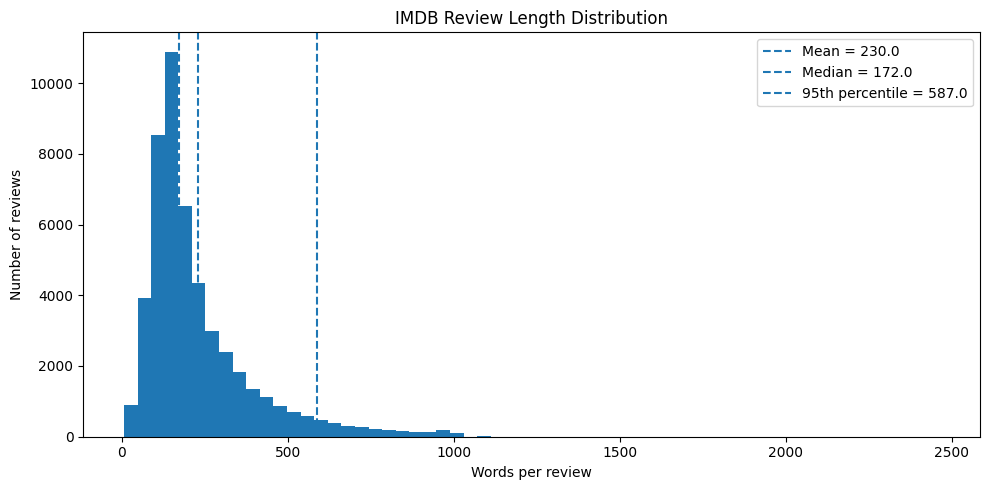

In [10]:
df['word_count'] = df['clean_review'].str.split().str.len()

mean_len = df['word_count'].mean()
median_len = df['word_count'].median()
p95_len = np.percentile(df['word_count'], 95)
MAXLEN = int(np.ceil(p95_len / 10) * 10)

print(f'Mean word count   : {mean_len:.2f}')
print(f'Median word count : {median_len:.2f}')
print(f'95th percentile   : {p95_len:.2f}')
print(f'Chosen MAXLEN     : {MAXLEN}')
print(f'Maximum word count: {df["word_count"].max()}')

plt.figure(figsize=(10, 5))
plt.hist(df['word_count'], bins=60)
plt.axvline(mean_len, linestyle='--', label=f'Mean = {mean_len:.1f}')
plt.axvline(median_len, linestyle='--', label=f'Median = {median_len:.1f}')
plt.axvline(p95_len, linestyle='--', label=f'95th percentile = {p95_len:.1f}')
plt.xlabel('Words per review')
plt.ylabel('Number of reviews')
plt.title('IMDB Review Length Distribution')
plt.legend()
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'length_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

**Figure interpretation**
- The distribution is strongly right-skewed: most reviews are much shorter than the longest reviews.
- The 95th percentile gives a practical compromise between retaining long-context information and avoiding excessive padding.
- The selected `MAXLEN` is the 95th percentile rounded upward, so most reviews are retained while extreme outliers are truncated.

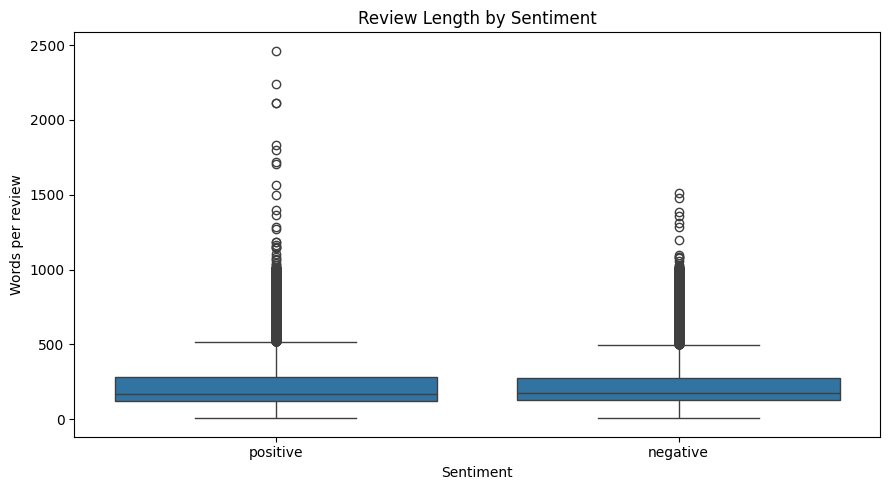

In [11]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='sentiment', y='word_count')
plt.xlabel('Sentiment')
plt.ylabel('Words per review')
plt.title('Review Length by Sentiment')
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'length_boxplot_by_sentiment.png', dpi=150, bbox_inches='tight')
plt.show()

**Figure interpretation**
- Positive and negative reviews have broadly similar length distributions, so padding length does not need to depend on sentiment.
- Both groups contain long-review outliers, reinforcing the need for a fixed maximum sequence length.
- The overall length distribution, rather than class membership, is therefore used to justify `MAXLEN`.

## 1.5 Tokenise

The tokenizer is fitted on **training texts only**. `num_words=10000` limits the vocabulary to the most useful frequent words, while the OOV token represents words not retained in the vocabulary.

In [12]:
# Encode target labels: positive = 1, negative = 0
df['label'] = (df['sentiment'] == 'positive').astype(int)

X_text = df['clean_review']
y = df['label'].values

X_train_text, X_test_text, y_train, y_test = train_test_split(X_text, y, test_size=0.2, random_state=42, stratify=y)

X_train_text = X_train_text.reset_index(drop=True)
X_test_text = X_test_text.reset_index(drop=True)

print('Training reviews:', len(X_train_text))
print('Test reviews    :', len(X_test_text))
print('Training class balance:')
print(pd.Series(y_train).value_counts().sort_index())

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train_text)

train_sequences = tokenizer.texts_to_sequences(X_train_text)
test_sequences = tokenizer.texts_to_sequences(X_test_text)

print('\nTop 10 words in tokenizer.word_index:')
print(list(tokenizer.word_index.items())[:10])
print('\nExample integer sequence:')
print(train_sequences[0])

Training reviews: 39665
Test reviews    : 9917
Training class balance:
0    19758
1    19907
Name: count, dtype: int64

Top 10 words in tokenizer.word_index:
[('<OOV>', 1), ('the', 2), ('and', 3), ('a', 4), ('of', 5), ('to', 6), ('is', 7), ('in', 8), ('it', 9), ('i', 10)]

Example integer sequence:
[10, 234, 27, 5, 1, 4935, 3, 10, 81, 158, 8, 32, 1, 454, 2767, 7929, 121, 2, 151, 10, 25, 105, 83, 705, 35, 1, 3781, 6, 547, 1, 25, 6453, 1909, 1, 20, 547, 1417, 1, 3, 25, 105, 438, 4986, 428, 605, 1742, 35, 1, 8533, 31, 1, 547, 10, 25, 81, 548, 438, 1, 4935, 109, 561, 12, 33, 79, 705, 43, 33, 5805, 547, 3, 100, 151, 8, 2, 1843, 10, 25, 111, 159, 105, 9, 576, 1204, 2, 899, 7, 9, 62, 1, 6, 5805, 547, 1, 38, 7, 2, 1918, 30, 1028, 1, 35, 2, 927, 20, 11, 1755, 2, 1755, 15, 1, 4935, 7, 4, 1527, 27, 22, 206, 1, 35, 547, 7, 21, 32, 5465, 2566, 1390, 22, 15, 11, 16, 3, 3499, 784, 20, 9]


## 1.6 Pad / truncate and split

The 80/20 stratified split is performed before tokenizer fitting. Sequences are padded and truncated from the **front** using `padding='pre'` and `truncating='pre'`, so the final time steps contain the most recent words when the recurrent cell reads the last state.

In [13]:
X_train = pad_sequences(train_sequences, maxlen=MAXLEN, padding='pre', truncating='pre')
X_test = pad_sequences(test_sequences, maxlen=MAXLEN, padding='pre', truncating='pre')

print('X_train shape:', X_train.shape)
print('y_train shape:', y_train.shape)
print('X_test shape :', X_test.shape)
print('y_test shape :', y_test.shape)

X_train shape: (39665, 590)
y_train shape: (39665,)
X_test shape : (9917, 590)
y_test shape : (9917,)


## 1.7 Why this is sequential data

A movie review is not just a collection of words. Word order changes meaning. For example, `the movie was not good` and `the movie was good, not bad` contain similar vocabulary but express different sentiment. A bag-of-words or order-blind model cannot fully represent this relationship, which motivates recurrent networks that process tokens sequentially.

---

# Task 2 — RNN Intuition, RNN vs ANN & Forward Propagation

**Objective:** Establish an order-blind ANN baseline and understand the recurrent hidden-state update through a manual NumPy implementation.

**Expected output:** ANN baseline metrics, RNN equations, a four-step NumPy forward pass, Keras verification, parameter-count verification and an ANN-versus-RNN comparison.

## 2.1 Baseline ANN on text

This is intentionally order-blind: `Embedding → Flatten → Dense → Dense`. Flatten treats each padded position as a fixed independent slot rather than sharing recurrent weights across time.

In [14]:
ann_model = Sequential([Input(shape=(MAXLEN,)),
                        Embedding(VOCAB_SIZE, EMBED_DIM),
                        Flatten(),
                        Dense(64, activation='relu'),
                        Dense(1, activation='sigmoid')])
ann_model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])
ann_model.summary()

ann_start = time.time()
ann_history = ann_model.fit(X_train, y_train, epochs=5, validation_split=0.1, batch_size=BATCH_SIZE, verbose=1)
ann_time_per_epoch = (time.time() - ann_start) / len(ann_history.history['loss'])
ann_prob = ann_model.predict(X_test, batch_size=BATCH_SIZE, verbose=0).ravel()
ann_pred = (ann_prob >= 0.5).astype(int)
ann_acc = accuracy_score(y_test, ann_pred)
ann_auc = roc_auc_score(y_test, ann_prob)

print(f'ANN test accuracy: {ann_acc:.4f}')
print(f'ANN ROC-AUC     : {ann_auc:.4f}')
print(f'ANN parameters  : {ann_model.count_params():,}')
print(f'ANN time/epoch  : {ann_time_per_epoch:.2f} s')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 590, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18880)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,208,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,528,449 (5.83 MB)

 Trainable params: 1,528,449 (5.83 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.8138 - loss: 0.3891 - val_accuracy: 0.8833 - val_loss: 0.2841
Epoch 2/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9433 - loss: 0.1551 - val_accuracy: 0.8646 - val_loss: 0.3755
Epoch 3/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9862 - loss: 0.0466 - val_accuracy: 0.8629 - val_loss: 0.4812
Epoch 4/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9971 - loss: 0.0117 - val_accuracy: 0.8568 - val_loss: 0.5684
Epoch 5/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9998 - loss: 0.0019 - val_accuracy: 0.8588 - val_loss: 0.6064
ANN test accuracy: 0.8634
ANN ROC-AUC     : 0.9388
ANN parameters  : 1,528,449
ANN time/epoch  : 3.79 s


## 2.2 RNN intuition

An RNN reads one time step at a time and carries a hidden state containing information from earlier tokens. The same weights are reused at every time step.

$$h_t = \tanh(W_{xh}x_t + W_{hh}h_{t-1} + b)$$

- $x_t$: input vector at time step $t$
- $h_{t-1}$: previous hidden state
- $W_{xh}$: input-to-hidden weights
- $W_{hh}$: recurrent hidden-to-hidden weights
- $b$: bias
- $h_t$: new hidden state

The output can be written as $y_t = f(W_{hy}h_t + b_y)$. Weight sharing keeps the parameter count independent of sequence length.

## 2.3 Manual forward propagation in NumPy

A small RNN cell is implemented from scratch with hidden size 3 and input size 2. The fixed seed and weights make the calculation reproducible.

h(1) = [-0.38764228 -0.95413177  0.4042915 ]
h(2) = [-0.58408135 -0.17994878  0.48472356]
h(3) = [-6.69536884e-01 -9.46717183e-01 -5.59973976e-04]
h(4) = [-0.86574174 -0.50825963  0.7751175 ]


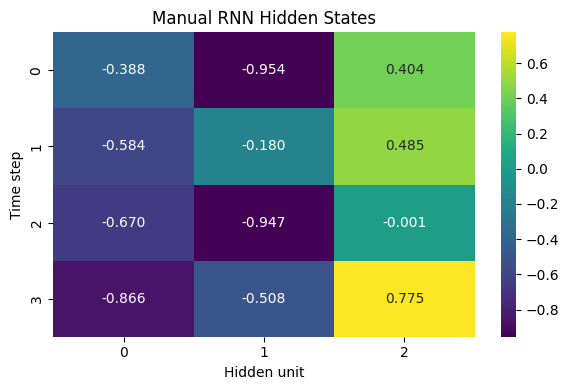

In [15]:
np.random.seed(42)
input_size = 2
hidden_size = 3
time_steps = 4

Wxh = np.random.randn(hidden_size, input_size) * 0.5
Whh = np.random.randn(hidden_size, hidden_size) * 0.5
b = np.random.randn(hidden_size) * 0.5
X_small = np.random.randn(time_steps, input_size)

h = np.zeros(hidden_size)
h_states = []
for t in range(time_steps):
    h = np.tanh(Wxh @ X_small[t] + Whh @ h + b)
    h_states.append(h.copy())
h_states = np.array(h_states)

for t, state in enumerate(h_states, start=1):
    print(f'h({t}) = {state}')

plt.figure(figsize=(6, 4))
sns.heatmap(h_states, annot=True, fmt='.3f', cmap='viridis', cbar=True)
plt.xlabel('Hidden unit')
plt.ylabel('Time step')
plt.title('Manual RNN Hidden States')

plt.tight_layout()
plt.savefig(PLOTS_DIR / 'rnn_forward_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

**Figure interpretation**
- Each row is the hidden state after one new input has been processed.
- Hidden values change over time because the current input is combined with the previous hidden state.
- The changing state illustrates how an RNN carries a compact summary of earlier inputs forward.

## 2.4 Verify against Keras

Keras stores the input kernel as `(input_size, units)`, while the manual calculation uses `Wxh` as `(units, input_size)`. Therefore `Wxh.T` is supplied to Keras.

In [16]:
keras_rnn = Sequential([Input(shape=(time_steps, input_size)),
                        SimpleRNN(hidden_size, return_sequences=True, use_bias=True)])
keras_rnn.layers[0].set_weights([Wxh.T, Whh.T, b])
keras_output = keras_rnn.predict(X_small[np.newaxis, ...], verbose=0)[0]

print('np.allclose(manual, Keras):', np.allclose(h_states, keras_output, atol=1e-6))
print('Maximum absolute difference:', np.max(np.abs(h_states - keras_output)))

np.allclose(manual, Keras): True
Maximum absolute difference: 1.3408886123666974e-07


## 2.5 Parameter count by formula

For `SimpleRNN(units=64)` with an embedding dimension of 32:

$$64 \times (32 + 64 + 1) = 6,208$$

The three terms are input weights, recurrent weights and bias. Unlike the flattened ANN, this count does not grow with `MAXLEN`.

In [17]:
rnn_expected_params = UNITS * (EMBED_DIM + UNITS + 1)
print('Formula parameter count:', rnn_expected_params)
print('SimpleRNN-only expected count:', rnn_expected_params)

Formula parameter count: 6208
SimpleRNN-only expected count: 6208


## 2.6 RNN vs ANN summary

| Aspect | ANN baseline | RNN |
|---|---|---|
| Input handling | Fixed flattened positions | Sequential time steps |
| Word order | Not explicitly modelled | Explicitly modelled |
| Weight sharing | No across positions | Yes across time |
| Parameters vs sequence length | Grows with MAXLEN after Flatten | Recurrent parameters are independent of MAXLEN |
| Memory | No recurrent memory | Hidden state carries prior information |
| Typical use | Tabular / fixed vectors | Text, speech, time series |

---

# Task 3 — Types of RNN & Sentiment Analysis with SimpleRNN

**Objective:** Demonstrate the four sequence input/output patterns and train the required many-to-one SimpleRNN sentiment classifier.

**Expected output:** Shape demonstrations, application table, trained SimpleRNN, learning curves, full evaluation metrics and learned embedding examples.

## 3.1 Types of RNN — shape demonstration

In [18]:
dummy = tf.random.normal((4, 10, 8), seed=SEED)

one_to_one = Dense(1)(dummy[:, 0, :])

one_to_many = Sequential([Input(shape=(8,)), RepeatVector(10), SimpleRNN(16, return_sequences=True)])(dummy[:, 0, :])
many_to_one = SimpleRNN(16, return_sequences=False)(dummy)
many_to_many = SimpleRNN(16, return_sequences=True)(dummy)

print('One-to-One :', one_to_one.shape)
print('One-to-Many:', one_to_many.shape)
print('Many-to-One:', many_to_one.shape)
print('Many-to-Many:', many_to_many.shape)

One-to-One : (4, 1)
One-to-Many: (4, 10, 16)
Many-to-One: (4, 16)
Many-to-Many: (4, 10, 16)


| Type | Input shape | Output shape | `return_sequences` | Example |
|---|---|---|---|---|
| One-to-One | `(batch, features)` | `(batch, output)` | Not applicable | Ordinary classification |
| One-to-Many | `(batch, features)` | `(batch, time, units)` | True | Image captioning |
| Many-to-One | `(batch, time, features)` | `(batch, units)` | False | Sentiment analysis |
| Many-to-Many | `(batch, time, features)` | `(batch, time, units)` | True | NER / sequence tagging |

**This project uses many-to-one because one complete movie review maps to one sentiment label.**

## 3.2 Match types to real problems

- One-to-One: fixed input to fixed output, such as ordinary classification.
- One-to-Many: one input produces a sequence, such as image captioning.
- Many-to-One: a sequence produces one output, such as movie-review sentiment.
- Many-to-Many: each time step produces an output, such as named-entity tagging or machine translation.

## 3.3 Build the SimpleRNN sentiment model

In [19]:
def build_model(cell_type='rnn', units=64, learning_rate=0.001, clipnorm=None, maxlen=MAXLEN):
    model = Sequential([Input(shape=(maxlen,)), Embedding(VOCAB_SIZE, EMBED_DIM)])

    if cell_type == 'rnn':
        model.add(SimpleRNN(units))
    elif cell_type == 'lstm':
        model.add(LSTM(units))
    elif cell_type == 'gru':
        model.add(GRU(units))
    else:
        raise ValueError('cell_type must be rnn, lstm or gru')
    model.add(Dense(1, activation='sigmoid'))
    optimizer = Adam(learning_rate=learning_rate, clipnorm=clipnorm) if clipnorm else Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
    return model

results = {}
roc_data = {}

class EpochTimer(Callback):
    def on_train_begin(self, logs=None):
        self.epoch_times = []
    def on_epoch_begin(self, epoch, logs=None):
        self._start = time.time()
    def on_epoch_end(self, epoch, logs=None):
        self.epoch_times.append(time.time() - self._start)

def evaluate_model(model, name, history, epoch_times=None, X_eval=X_test, y_eval=y_test):
    prob = model.predict(X_eval, batch_size=BATCH_SIZE, verbose=0).ravel()
    pred = (prob >= 0.5).astype(int)
    report = classification_report(y_eval, pred, output_dict=True, zero_division=0)
    metrics = {'Model': name,
               'Parameters': model.count_params(),
               'Time per Epoch (s)': float(np.mean(epoch_times)) if epoch_times else np.nan,
               'Epochs Trained': len(history.history['loss']) if history else np.nan,
               'Test Accuracy': accuracy_score(y_eval, pred),
               'Precision': precision_score(y_eval, pred, zero_division=0),
               'Recall': recall_score(y_eval, pred, zero_division=0),
               'F1': f1_score(y_eval, pred, zero_division=0),
               'ROC-AUC': roc_auc_score(y_eval, prob)}

    results[name] = metrics
    roc_data[name] = (y_eval.copy(), prob.copy())
    print(classification_report(y_eval, pred, target_names=['negative', 'positive'], zero_division=0))
    print('Confusion matrix:\n', confusion_matrix(y_eval, pred))
    print(f"ROC-AUC: {metrics['ROC-AUC']:.4f}")
    return metrics, prob, pred

rnn_model = build_model('rnn', units=64)
rnn_model.summary()
print('Verified SimpleRNN formula:', rnn_model.get_layer(index=2).count_params(), 'vs', rnn_expected_params)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 590, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_4 (SimpleRNN)        │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 326,273 (1.24 MB)

 Trainable params: 326,273 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

Verified SimpleRNN formula: 65 vs 6208


## 3.4 Train and plot SimpleRNN

The same batch size, optimiser and early-stopping settings are used for the recurrent models so the comparison remains controlled.

Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 30s 48ms/step - accuracy: 0.6399 - loss: 0.6210 - val_accuracy: 0.7570 - val_loss: 0.5170
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 25s 44ms/step - accuracy: 0.7108 - loss: 0.5583 - val_accuracy: 0.6776 - val_loss: 0.5929
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 25s 45ms/step - accuracy: 0.7344 - loss: 0.5279 - val_accuracy: 0.7976 - val_loss: 0.4523
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 25s 44ms/step - accuracy: 0.7844 - loss: 0.4669 - val_accuracy: 0.7704 - val_loss: 0.4898
Epoch 5/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 25s 44ms/step - accuracy: 0.7284 - loss: 0.5245 - val_accuracy: 0.6249 - val_loss: 0.6266
Epoch 6/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 25s 44ms/step - accuracy: 0.7604 - loss: 0.4863 - val_accuracy: 0.7756 - val_loss: 0.5111


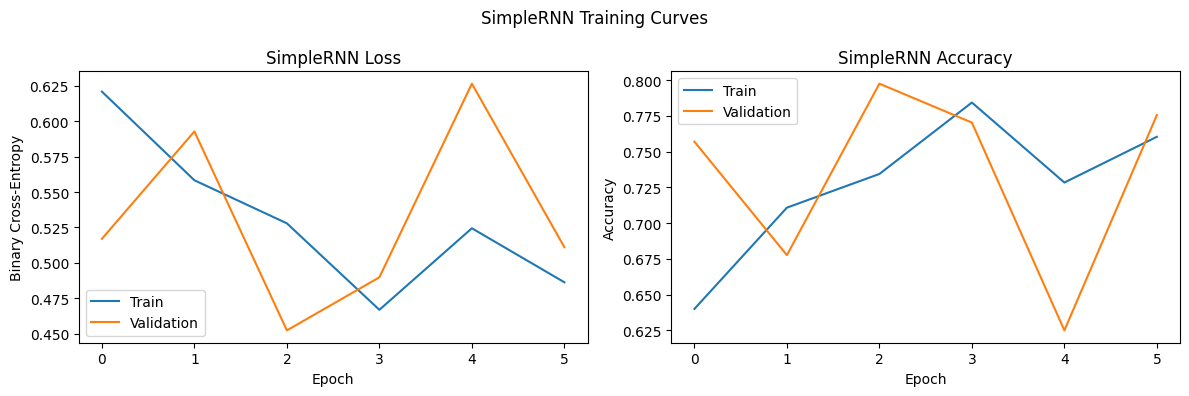

Total training time: 153.65 s
Mean time per epoch: 25.58 s


In [20]:
rnn_timer = EpochTimer()
rnn_es = EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True)
rnn_start = time.time()
rnn_history = rnn_model.fit(X_train, y_train, epochs=MAIN_EPOCHS, batch_size=BATCH_SIZE, validation_split=0.1, callbacks=[rnn_es, rnn_timer], verbose=1)
rnn_total = time.time() - rnn_start

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(rnn_history.history['loss'], label='Train')
axes[0].plot(rnn_history.history['val_loss'], label='Validation')
axes[0].set_title('SimpleRNN Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Binary Cross-Entropy')
axes[0].legend()
axes[1].plot(rnn_history.history['accuracy'], label='Train')
axes[1].plot(rnn_history.history['val_accuracy'], label='Validation')
axes[1].set_title('SimpleRNN Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

fig.suptitle('SimpleRNN Training Curves')
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'training_curves_rnn.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Total training time: {rnn_total:.2f} s')
print(f'Mean time per epoch: {np.mean(rnn_timer.epoch_times):.2f} s')

**Figure interpretation**
- The training and validation curves show whether the SimpleRNN is learning useful sentiment patterns and whether validation performance begins to diverge.
- A persistent gap between training and validation curves indicates overfitting, while both curves remaining near chance indicates difficulty learning long-range dependencies.
- The exact conclusion should be based on the displayed curves after the notebook is run.

## 3.5 Evaluate SimpleRNN

              precision    recall  f1-score   support

    negative       0.78      0.82      0.80      4940
    positive       0.81      0.77      0.79      4977

    accuracy                           0.80      9917
   macro avg       0.80      0.80      0.80      9917
weighted avg       0.80      0.80      0.80      9917

Confusion matrix:
 [[4041  899]
 [1124 3853]]
ROC-AUC: 0.8738


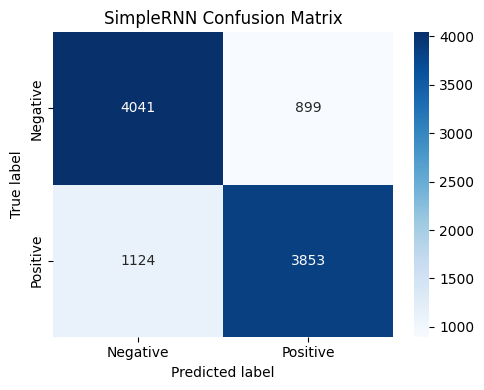

In [21]:
rnn_metrics, rnn_prob, rnn_pred = evaluate_model(rnn_model, 'SimpleRNN', rnn_history, rnn_timer.epoch_times)

cm = confusion_matrix(y_test, rnn_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('SimpleRNN Confusion Matrix')

plt.tight_layout()
plt.savefig(PLOTS_DIR / 'confusion_matrix_rnn.png', dpi=150, bbox_inches='tight')
plt.show()

**Figure interpretation**
- The diagonal cells are correct predictions; the off-diagonal cells are false positives and false negatives.
- Because the dataset is balanced, the two error types can be compared directly without a large class-frequency distortion.
- The exact error balance should be read from the displayed matrix and classification report.

## 3.6 Embedding layer

The Embedding layer maps each integer token ID to a learned 32-dimensional vector. These vectors are trained from scratch with the sentiment model; no pretrained embeddings are used.

In [22]:
embedding_weights = rnn_model.get_layer(index=0).get_weights()[0]

for word in ['good', 'bad']:
    idx = tokenizer.word_index.get(word)
    if idx is not None and idx < embedding_weights.shape[0]:
        print(f'\n{word!r} token id: {idx}')
        print(embedding_weights[idx])


'good' token id: 49
[-0.03995651 -0.02268073 -0.01166606  0.09217211  0.03288994 -0.02844242
 -0.01891695 -0.03572053 -0.05946932  0.05805095  0.05992718  0.0280716
  0.03124931  0.08674172  0.0168139   0.04996502 -0.05976667 -0.01707054
 -0.05254152  0.04026866 -0.03258474 -0.0186487   0.0537152  -0.06860542
 -0.03689544  0.09280375 -0.01099532 -0.0762312   0.07652099 -0.00252288
 -0.06732852 -0.01086371]

'bad' token id: 74
[ 0.03813699 -0.06184227  0.23215978 -0.28335434 -0.28166315 -0.13563973
  0.12265579  0.16653167 -0.07863881 -0.16731401 -0.30100468 -0.1821603
 -0.09105591 -0.252238   -0.1807662   0.00962673  0.12535667 -0.17456354
  0.20825064 -0.2746533  -0.1463337   0.1987945  -0.24257919  0.00299226
  0.1824261  -0.1620268   0.13496864  0.23904781 -0.18112029 -0.14037606
  0.04351239  0.17655587]


---

# Task 4 — Backpropagation Through Time & Problems with RNN

**Objective:** Explain BPTT and experimentally observe vanishing gradients, sequence-length limitations and exploding gradients.

**Expected output:** BPTT explanation, per-time-step gradient plot, sequence-length accuracy experiment, gradient-clipping comparison and a problem/remedy summary.

## 4.1 BPTT

Backpropagation Through Time (BPTT) unrolls an RNN across its time steps. The same recurrent weights appear at every step, so the loss gradient is propagated through the entire unrolled chain. The gradient reaching an early hidden state contains a product of Jacobian terms:

$$\frac{\partial L}{\partial h_1} = \frac{\partial L}{\partial h_T} \prod_t \left(W_{hh}^T \operatorname{diag}(1-h_t^2)\right)$$

The shared-weight gradient is the sum of contributions from the different time steps.

## 4.2 Vanishing and exploding gradients

If the repeated Jacobian factors have magnitudes mostly below 1, their product shrinks exponentially and early tokens contribute very little to learning: the **vanishing-gradient problem**. If the factors become larger than 1, the product can grow rapidly and produce unstable or NaN losses: the **exploding-gradient problem**. This explains the short effective memory of a basic SimpleRNN on long sequences.

## 4.3 Measure gradient flow with GradientTape

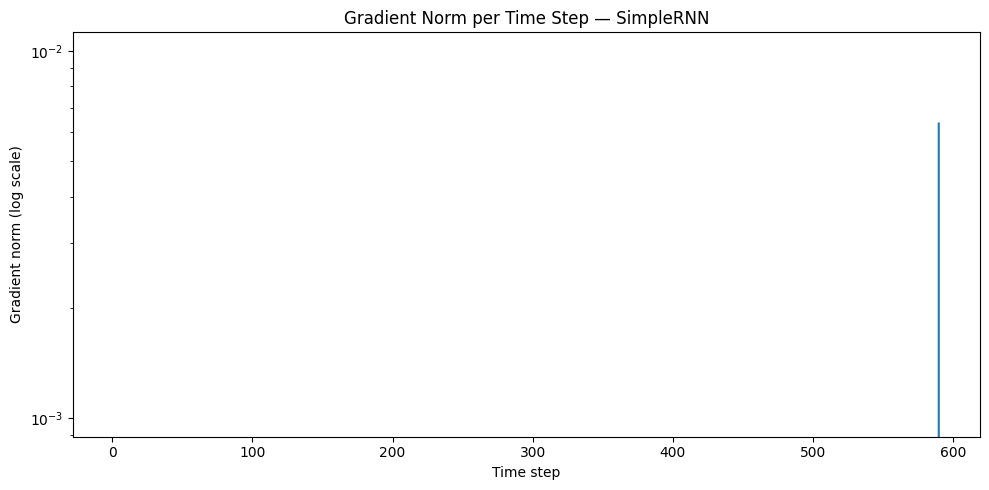

In [23]:
def gradient_norms(model, X_batch, y_batch, cell_type):
    inputs = Input(shape=(MAXLEN,))
    emb = Embedding(VOCAB_SIZE, EMBED_DIM)(inputs)
    if cell_type == 'rnn':
        cell = SimpleRNN(UNITS, return_sequences=True)
    elif cell_type == 'lstm':
        cell = LSTM(UNITS, return_sequences=True)
    elif cell_type == 'gru':
        cell = GRU(UNITS, return_sequences=True)
    else:
        raise ValueError(cell_type)

    H = cell(emb)
    last_h = H[:, -1, :]
    output = Dense(1, activation='sigmoid')(last_h)
    grad_model = Model(inputs, [H, output])
    grad_model.set_weights(model.get_weights())

    xb = tf.convert_to_tensor(X_batch)
    yb = tf.convert_to_tensor(y_batch.reshape(-1, 1), dtype=tf.float32)
    with tf.GradientTape() as tape:
        H_val, pred = grad_model(xb, training=False)
        tape.watch(H_val)
        loss = tf.reduce_mean(tf.keras.losses.binary_crossentropy(yb, pred))
    grads = tape.gradient(loss, H_val)
    norms = tf.norm(grads, axis=-1)
    return tf.reduce_mean(norms, axis=0).numpy()

X_grad = X_test[:64]
y_grad = y_test[:64]
rnn_grad_norms = gradient_norms(rnn_model, X_grad, y_grad, 'rnn')

plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, MAXLEN + 1), rnn_grad_norms)
plt.yscale('log')
plt.xlabel('Time step')
plt.ylabel('Gradient norm (log scale)')
plt.title('Gradient Norm per Time Step — SimpleRNN')

plt.tight_layout()
plt.savefig(PLOTS_DIR / 'gradient_norms_rnn.png', dpi=150, bbox_inches='tight')
plt.show()

**Figure interpretation**
- The log-scale curve shows how much gradient signal reaches each time step when the prediction is based on the final hidden state.
- A strong reduction toward earlier steps is evidence that the SimpleRNN struggles to transmit learning signals through long sequences.
- This experimentally connects the BPTT product-of-Jacobians explanation to the model's observed gradient flow.

## 4.4 Accuracy vs sequence length

50 0.7529
100 0.7621
200 0.7345
300 0.7160


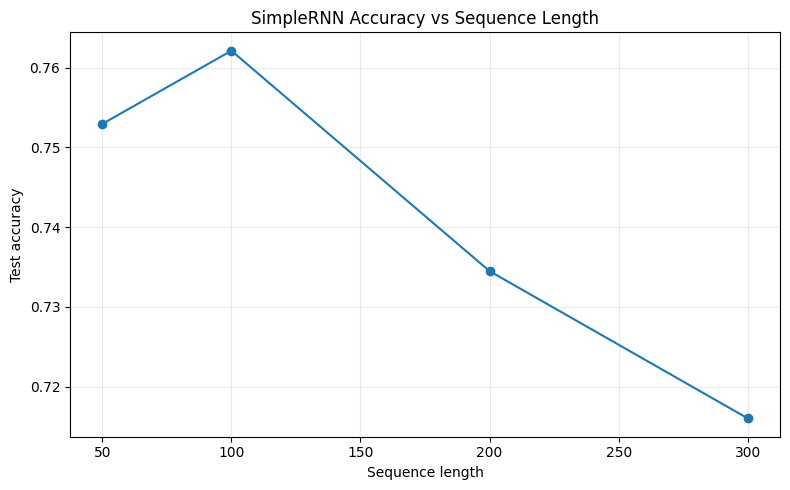

In [24]:
sequence_lengths = [50, 100, 200, 300]
seq_length_results = []

for seq_len in sequence_lengths:
    Xtr_len = pad_sequences(train_sequences, maxlen=seq_len, padding='pre', truncating='pre')
    Xte_len = pad_sequences(test_sequences, maxlen=seq_len, padding='pre', truncating='pre')

    np.random.seed(SEED); tf.random.set_seed(SEED)
    m = build_model('rnn', units=64, maxlen=seq_len)
    h = m.fit(Xtr_len, y_train, epochs=8, batch_size=BATCH_SIZE, validation_split=0.1, verbose=0)
    p = m.predict(Xte_len, batch_size=BATCH_SIZE, verbose=0).ravel()
    acc = accuracy_score(y_test, (p >= 0.5).astype(int))
    seq_length_results.append({'MAXLEN': seq_len, 'Test Accuracy': acc})
    print(seq_len, f'{acc:.4f}')

seq_length_df = pd.DataFrame(seq_length_results)
plt.figure(figsize=(8, 5))
plt.plot(seq_length_df['MAXLEN'], seq_length_df['Test Accuracy'], marker='o')
plt.xlabel('Sequence length')
plt.ylabel('Test accuracy')
plt.title('SimpleRNN Accuracy vs Sequence Length')
plt.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(PLOTS_DIR / 'accuracy_vs_sequence_length.png', dpi=150, bbox_inches='tight')
plt.show()

**Figure interpretation**
- Increasing the padded sequence length does not guarantee better accuracy because a basic RNN has difficulty carrying information across many time steps.
- Longer sequences can introduce additional tokens that are weakly relevant or noisy while increasing recurrent computation.
- The best sequence length should therefore be selected from observed validation/test behaviour rather than from length alone.

## 4.5 Exploding-gradient demonstration and clipping

A deliberately aggressive learning rate is used to make optimisation unstable. The second run applies `clipnorm=1.0`, which rescales gradients whose norm exceeds the threshold.

Epoch 1/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 29s 48ms/step - accuracy: 0.5558 - loss: 0.7012 - val_accuracy: 0.5543 - val_loss: 0.7489
Epoch 2/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 24s 44ms/step - accuracy: 0.5774 - loss: 0.6883 - val_accuracy: 0.5372 - val_loss: 0.7809
Epoch 3/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 24s 44ms/step - accuracy: 0.5833 - loss: 0.6859 - val_accuracy: 0.5397 - val_loss: 0.7555
Epoch 4/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 24s 44ms/step - accuracy: 0.5918 - loss: 0.6810 - val_accuracy: 0.5425 - val_loss: 0.7556
Epoch 5/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 41s 44ms/step - accuracy: 0.6004 - loss: 0.6698 - val_accuracy: 0.5521 - val_loss: 0.7566
Epoch 1/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 30s 49ms/step - accuracy: 0.5260 - loss: 0.7251 - val_accuracy: 0.5253 - val_loss: 0.7059
Epoch 2/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 25s 44ms/step - accuracy: 0.5670 - loss: 0.6917 - val_accuracy: 0.5364 - val_loss: 0.7260
Epoch 3/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 25s 44ms/step - accuracy: 0.5899 - loss: 0.6756 - val_accu

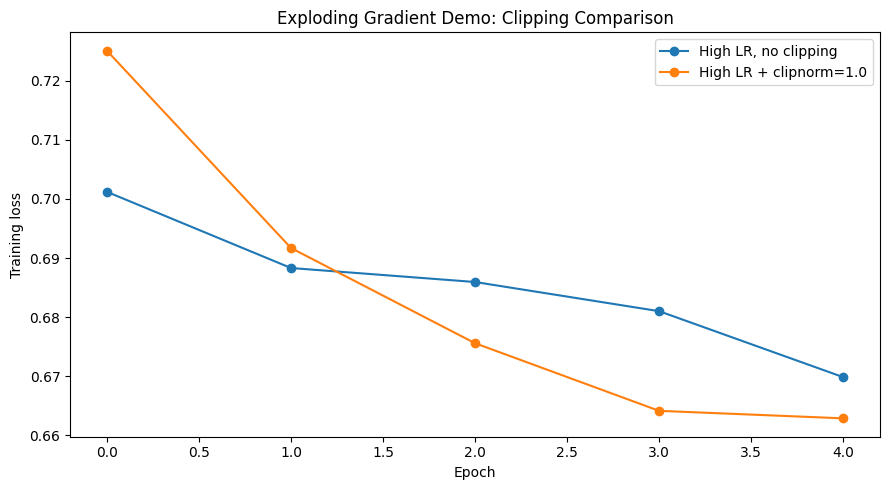

In [25]:
np.random.seed(SEED); tf.random.set_seed(SEED)
exploding_model = build_model('rnn', units=64, learning_rate=0.05)
exploding_history = exploding_model.fit(X_train, y_train, epochs=5, batch_size=BATCH_SIZE, validation_split=0.1, verbose=1)

np.random.seed(SEED); tf.random.set_seed(SEED)
clipped_model = build_model('rnn', units=64, learning_rate=0.05, clipnorm=1.0)
clipped_history = clipped_model.fit(X_train, y_train, epochs=5, batch_size=BATCH_SIZE, validation_split=0.1, verbose=1)

plt.figure(figsize=(9, 5))
plt.plot(exploding_history.history['loss'], marker='o', label='High LR, no clipping')
plt.plot(clipped_history.history['loss'], marker='o', label='High LR + clipnorm=1.0')
plt.xlabel('Epoch')
plt.ylabel('Training loss')
plt.title('Exploding Gradient Demo: Clipping Comparison')
plt.legend()

plt.tight_layout()
plt.savefig(PLOTS_DIR / 'exploding_gradient_clipping.png', dpi=150, bbox_inches='tight')
plt.show()

**Figure interpretation**
- The unclipped run is intentionally aggressive and may show large loss spikes or unstable values.
- Gradient clipping limits the size of the update and can stabilise exploding-gradient behaviour.
- Clipping does not solve vanishing gradients; it is a remedy for excessively large gradients, not weak gradients.

## 4.6 Problems summary

| Problem | Cause | Symptom | Remedy |
|---|---|---|---|
| Vanishing gradient | Repeated factors below 1 | Early-time-step gradients collapse | LSTM / GRU gating |
| Exploding gradient | Repeated factors above 1 | Loss spikes or NaN | Gradient clipping |
| Slow sequential training | Time steps processed sequentially | Higher training time | Smaller sequences / GPU |
| Short-term memory | Weak long-range state retention | Earlier words have little influence | Gated recurrent cells |

---

# Task 5 — LSTM: Long Short-Term Memory

**Objective:** Understand LSTM gates and cell state, verify its parameter formula, implement one LSTM step manually, train the model and compare gradient flow with SimpleRNN.

**Expected output:** LSTM equations, manual four-step calculation, trained/evaluated LSTM, gradient comparison and stacked LSTM experiment.

## 5.1 LSTM theory

An LSTM maintains a cell state $C_t$ and hidden state $h_t$. The gates control what to forget, what to write and what to reveal:

$$f_t = \sigma(W_f[h_{t-1},x_t]+b_f)$$
$$i_t = \sigma(W_i[h_{t-1},x_t]+b_i)$$
$$g_t = \tanh(W_g[h_{t-1},x_t]+b_g)$$
$$C_t = f_t*C_{t-1}+i_t*g_t$$
$$o_t = \sigma(W_o[h_{t-1},x_t]+b_o)$$
$$h_t = o_t*\tanh(C_t)$$

In plain language, the forget gate decides what old information to discard, the input gate decides what new information to write, and the output gate decides what part of the cell state becomes the hidden output.

## 5.2 Why LSTM mitigates vanishing gradients

The cell state has an additive update path. When the forget gate stays close to 1, the cell-state gradient can pass through many time steps with much less attenuation than the repeated matrix-and-`tanh` path of a SimpleRNN. This provides a practical mechanism for preserving long-range information.

## 5.3 Parameter count by formula

An LSTM has four sets of weights. Therefore:

$$4 \times units \times (embedding\_dim + units + 1)$$

For 64 units and 32-dimensional embeddings this gives 24,832 recurrent-cell parameters, exactly four times the SimpleRNN cell count.

In [26]:
lstm_expected_params = 4 * UNITS * (EMBED_DIM + UNITS + 1)
print('Expected LSTM cell parameters:', lstm_expected_params)

Expected LSTM cell parameters: 24832


## 5.4 Manual single-step LSTM in NumPy

In [27]:
np.random.seed(SEED)
hs, ins = 3, 2
Wf, Wi, Wg, Wo = [np.random.randn(hs, hs + ins) * 0.5 for _ in range(4)]
bf, bi, bg, bo = [np.random.randn(hs) * 0.5 for _ in range(4)]
X_lstm = np.random.randn(4, ins)
h = np.zeros(hs)
C = np.zeros(hs)
rows = []

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

for t in range(4):
    z = np.concatenate([h, X_lstm[t]])
    f = sigmoid(Wf @ z + bf)
    i = sigmoid(Wi @ z + bi)
    g = np.tanh(Wg @ z + bg)
    o = sigmoid(Wo @ z + bo)
    C = f * C + i * g
    h = o * np.tanh(C)
    rows.append([t + 1, f, i, o, C.copy(), h.copy()])

for t, f, i, o, C, h in rows:
    print(f'Time {t}')
    print('  f =', f)
    print('  i =', i)
    print('  o =', o)
    print('  C =', C)
    print('  h =', h)

print('\nWhen f is close to 1 and i is close to 0, the previous cell state is largely preserved.')

Time 1
  f = [0.38934829 0.58419946 0.13373441]
  i = [0.15620849 0.50147549 0.61317569]
  o = [0.15342591 0.72637627 0.82146059]
  C = [ 0.08678844  0.29649131 -0.45921342]
  h = [ 0.01328226  0.20926785 -0.35277042]
Time 2
  f = [0.07898642 0.68425765 0.7594454 ]
  i = [0.46151756 0.88318936 0.76115902]
  o = [0.14974285 0.47113937 0.67016281]
  C = [ 0.44735697  1.07783104 -0.34048253]
  h = [ 0.06285067  0.37332772 -0.21975182]
Time 3
  f = [0.44530534 0.50218102 0.37598094]
  i = [0.33900389 0.60399392 0.60896033]
  o = [0.43320623 0.51645976 0.63278371]
  C = [0.24080367 0.87852187 0.13222878]
  h = [0.10234701 0.36445431 0.08318795]
Time 4
  f = [0.52252252 0.41439099 0.72606086]
  i = [0.63726034 0.71474913 0.6796152 ]
  o = [0.79713437 0.28954943 0.42472714]
  C = [-0.21449851  0.46295352  0.73177048]
  h = [-0.16840921  0.12522675  0.2650923 ]

When f is close to 1 and i is close to 0, the previous cell state is largely preserved.


## 5.5 Build, train and evaluate LSTM

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_9 (Embedding)         │ (None, 590, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 344,897 (1.32 MB)

 Trainable params: 344,897 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

LSTM recurrent-cell parameters: 65
Formula result: 24832
Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 16s 24ms/step - accuracy: 0.7783 - loss: 0.4743 - val_accuracy: 0.8364 - val_loss: 0.3999
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 13s 23ms/step - accuracy: 0.8841 - loss: 0.2905 - val_accuracy: 0.8828 - val_loss: 0.3235
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 13s 23ms/step - accuracy: 0.9128 - loss: 0.2314 - val_accuracy: 0.8737 - val_loss: 0.3063
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 13s 23ms/step - accuracy: 0.9262 - loss: 0.1986 - val_accuracy: 0.8737 - val_loss: 0.3087
Epoch 5/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 13s 23ms/step - accuracy: 0.9351 - loss: 0.1785 - val_accuracy: 0.8669 - val_loss: 0.3397
Epoch 6/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 13s 23ms/step - accuracy: 0.9278 - loss: 0.1950 - val_accuracy: 0.8634 - val_loss: 0.3940


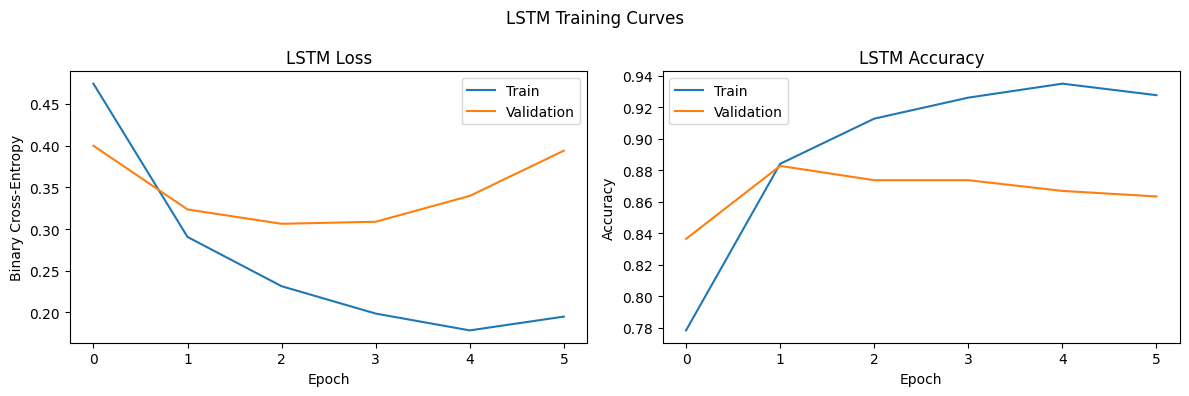

              precision    recall  f1-score   support

    negative       0.86      0.92      0.88      4940
    positive       0.91      0.85      0.88      4977

    accuracy                           0.88      9917
   macro avg       0.88      0.88      0.88      9917
weighted avg       0.88      0.88      0.88      9917

Confusion matrix:
 [[4521  419]
 [ 758 4219]]
ROC-AUC: 0.9489


In [28]:
lstm_model = build_model('lstm', units=64)
lstm_model.summary()
print('LSTM recurrent-cell parameters:', lstm_model.get_layer(index=2).count_params())
print('Formula result:', lstm_expected_params)

lstm_timer = EpochTimer()
lstm_es = EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True)
lstm_start = time.time()
lstm_history = lstm_model.fit(X_train, y_train, epochs=MAIN_EPOCHS, batch_size=BATCH_SIZE, validation_split=0.1, callbacks=[lstm_es, lstm_timer], verbose=1)
lstm_total = time.time() - lstm_start

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(lstm_history.history['loss'], label='Train')
axes[0].plot(lstm_history.history['val_loss'], label='Validation')
axes[0].set_title('LSTM Loss')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Binary Cross-Entropy'); axes[0].legend()
axes[1].plot(lstm_history.history['accuracy'], label='Train')
axes[1].plot(lstm_history.history['val_accuracy'], label='Validation')
axes[1].set_title('LSTM Accuracy')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy'); axes[1].legend()

fig.suptitle('LSTM Training Curves')
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'training_curves_lstm.png', dpi=150, bbox_inches='tight')
plt.show()

lstm_metrics, lstm_prob, lstm_pred = evaluate_model(lstm_model, 'LSTM', lstm_history, lstm_timer.epoch_times)

**Figure interpretation**
- The LSTM curves show whether gated memory improves learning and validation behaviour compared with the SimpleRNN.
- Training and validation trends should be compared with the SimpleRNN using the same axes interpretation rather than relying on training accuracy alone.
- The recorded epoch time also reveals the computational cost of the additional gates.

## 5.6 Gradient-flow comparison: SimpleRNN vs LSTM

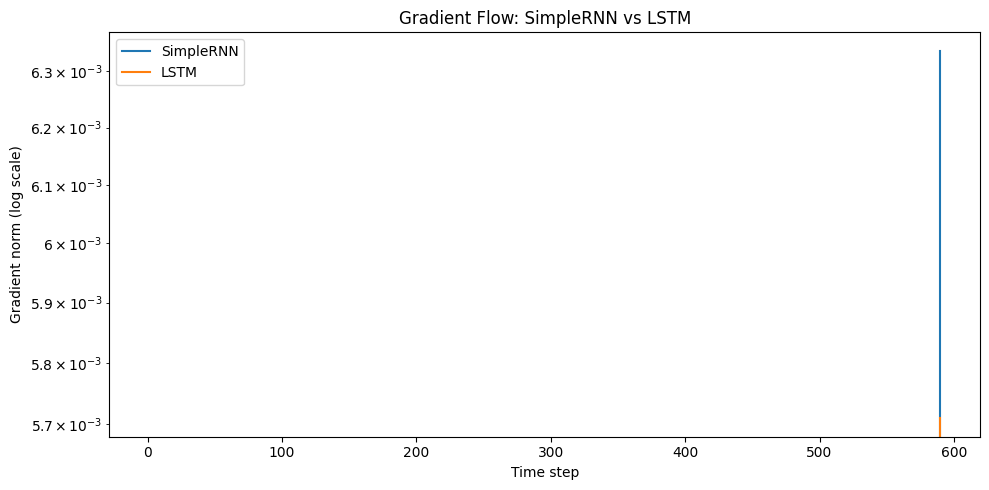

Earliest-step SimpleRNN gradient: 0.0
Earliest-step LSTM gradient     : 0.0
LSTM / SimpleRNN ratio          : 0.0


In [29]:
lstm_grad_norms = gradient_norms(lstm_model, X_grad, y_grad, 'lstm')

plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, MAXLEN + 1), rnn_grad_norms, label='SimpleRNN')
plt.plot(np.arange(1, MAXLEN + 1), lstm_grad_norms, label='LSTM')
plt.yscale('log')
plt.xlabel('Time step')
plt.ylabel('Gradient norm (log scale)')
plt.title('Gradient Flow: SimpleRNN vs LSTM')

plt.legend()
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'gradient_norms_rnn_lstm.png', dpi=150, bbox_inches='tight')
plt.show()

print('Earliest-step SimpleRNN gradient:', rnn_grad_norms[0])
print('Earliest-step LSTM gradient     :', lstm_grad_norms[0])
print('LSTM / SimpleRNN ratio          :', lstm_grad_norms[0] / max(rnn_grad_norms[0], 1e-30))

**Figure interpretation**
- The LSTM curve should generally retain stronger gradient signal at earlier time steps than the SimpleRNN curve.
- The log scale makes orders-of-magnitude differences visible even when the raw values are small.
- The printed earliest-step ratio provides a quantitative complement to the visual comparison.

## 5.7 Stacked LSTM

The first LSTM returns the full sequence because the second LSTM needs a sequence of hidden states as its input. The second LSTM then reduces that sequence to its final hidden representation.

In [30]:
stacked_lstm = Sequential([Input(shape=(MAXLEN,)),
                           Embedding(VOCAB_SIZE, EMBED_DIM),
                           LSTM(64, return_sequences=True),
                           LSTM(32),
                           Dense(1, activation='sigmoid')])

stacked_lstm.compile(optimizer=Adam(0.001), loss='binary_crossentropy', metrics=['accuracy'])
stacked_timer = EpochTimer()
stacked_es = EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True)
stacked_history = stacked_lstm.fit(X_train, y_train, epochs=MAIN_EPOCHS, batch_size=BATCH_SIZE, validation_split=0.1, callbacks=[stacked_es, stacked_timer], verbose=1)
stacked_metrics, stacked_prob, stacked_pred = evaluate_model(stacked_lstm, 'Stacked LSTM', stacked_history, stacked_timer.epoch_times)

print('Stacked LSTM parameters:', stacked_lstm.count_params())
print('Mean time per epoch:', np.mean(stacked_timer.epoch_times))

Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 24s 41ms/step - accuracy: 0.6057 - loss: 0.6329 - val_accuracy: 0.5021 - val_loss: 0.6913
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 22s 40ms/step - accuracy: 0.6257 - loss: 0.6397 - val_accuracy: 0.8046 - val_loss: 0.4286
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 23s 40ms/step - accuracy: 0.8332 - loss: 0.3868 - val_accuracy: 0.8530 - val_loss: 0.3482
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 41s 40ms/step - accuracy: 0.8976 - loss: 0.2605 - val_accuracy: 0.8800 - val_loss: 0.3022
Epoch 5/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 41s 39ms/step - accuracy: 0.9165 - loss: 0.2201 - val_accuracy: 0.8767 - val_loss: 0.3564
Epoch 6/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 28s 50ms/step - accuracy: 0.9269 - loss: 0.1938 - val_accuracy: 0.8485 - val_loss: 0.4140
Epoch 7/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 36s 40ms/step - accuracy: 0.9187 - loss: 0.2128 - val_accuracy: 0.8737 - val_loss: 0.3220
              precision    recall  f1-score   support

    negative       0.88      0.90  

# Task 6 — GRU: Gated Recurrent Unit

**Objective:** Understand the two-gate GRU, compare it with LSTM, train it under the same conditions and study gradient flow and hidden-unit sensitivity.

**Expected output:** GRU theory, comparison table, parameter verification, trained/evaluated GRU, three-way gradient plot and sensitivity plots.

## 6.1 GRU theory

A GRU has an update gate and a reset gate and does not maintain a separate cell state:

$$z_t = \sigma(W_z[h_{t-1},x_t])$$
$$r_t = \sigma(W_r[h_{t-1},x_t])$$
$$\tilde{h}_t = \tanh(W[r_t*h_{t-1},x_t])$$
$$h_t = (1-z_t)*h_{t-1}+z_t*\tilde{h}_t$$

The update gate controls how much old information is retained versus replaced. The reset gate controls how much past information is used when forming the candidate state.

## 6.2 GRU vs LSTM

| Aspect | LSTM | GRU |
|---|---|---|
| Gates | Forget, input, output | Update, reset |
| Separate cell state | Yes | No |
| Same hidden size | More parameters | Fewer parameters |
| Training speed | Usually higher cost | Usually lighter |
| Typical preference | Richer explicit memory control | Efficient gated sequence modelling |

The GRU combines the roles of the LSTM forget and input gates into its update gate.

## 6.3 GRU parameter count by formula

With Keras `reset_after=True`, there are three weight sets and two bias vectors per set:

$$3 \times (units\times embedding\_dim + units\times units + 2\times units)$$

For 64 units and 32-dimensional embeddings: $3\times(2048+4096+128)=18,816$.

In [31]:
gru_expected_params = 3 * (UNITS * EMBED_DIM + UNITS * UNITS + 2 * UNITS)
print('Expected GRU cell parameters:', gru_expected_params)

Expected GRU cell parameters: 18816


## 6.4 Build, train and evaluate GRU

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_12 (Embedding)        │ (None, 590, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        18,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 338,881 (1.29 MB)

 Trainable params: 338,881 (1.29 MB)

 Non-trainable params: 0 (0.00 B)

GRU recurrent-cell parameters: 65
Formula result: 18816
Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.7935 - loss: 0.4333 - val_accuracy: 0.8626 - val_loss: 0.3267
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 12s 22ms/step - accuracy: 0.8924 - loss: 0.2706 - val_accuracy: 0.8818 - val_loss: 0.3086
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 13s 23ms/step - accuracy: 0.9230 - loss: 0.2055 - val_accuracy: 0.8916 - val_loss: 0.2866
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 14s 25ms/step - accuracy: 0.9399 - loss: 0.1663 - val_accuracy: 0.8724 - val_loss: 0.4187
Epoch 5/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 13s 24ms/step - accuracy: 0.9470 - loss: 0.1466 - val_accuracy: 0.8921 - val_loss: 0.3536
Epoch 6/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 13s 23ms/step - accuracy: 0.9580 - loss: 0.1205 - val_accuracy: 0.8576 - val_loss: 0.4391


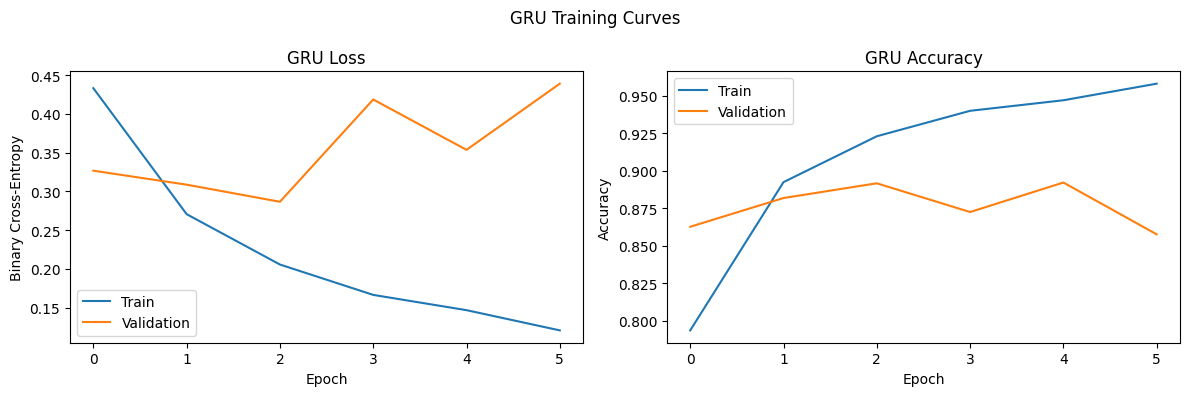

              precision    recall  f1-score   support

    negative       0.90      0.89      0.90      4940
    positive       0.89      0.90      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917

Confusion matrix:
 [[4410  530]
 [ 503 4474]]
ROC-AUC: 0.9564


In [32]:
gru_model = build_model('gru', units=64)
gru_model.summary()
print('GRU recurrent-cell parameters:', gru_model.get_layer(index=2).count_params())
print('Formula result:', gru_expected_params)

gru_timer = EpochTimer()
gru_es = EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True)
gru_start = time.time()
gru_history = gru_model.fit(X_train, y_train, epochs=MAIN_EPOCHS, batch_size=BATCH_SIZE, validation_split=0.1, callbacks=[gru_es, gru_timer], verbose=1)
gru_total = time.time() - gru_start

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(gru_history.history['loss'], label='Train')
axes[0].plot(gru_history.history['val_loss'], label='Validation')
axes[0].set_title('GRU Loss')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Binary Cross-Entropy'); axes[0].legend()
axes[1].plot(gru_history.history['accuracy'], label='Train')
axes[1].plot(gru_history.history['val_accuracy'], label='Validation')
axes[1].set_title('GRU Accuracy')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy'); axes[1].legend()

fig.suptitle('GRU Training Curves')
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'training_curves_gru.png', dpi=150, bbox_inches='tight')
plt.show()

gru_metrics, gru_prob, gru_pred = evaluate_model(gru_model, 'GRU', gru_history, gru_timer.epoch_times)

**Figure interpretation**
- The GRU curves show whether a lighter gated architecture can learn sentiment effectively under the same training setup.
- Compare validation accuracy and loss with the LSTM and SimpleRNN rather than judging only the final training score.
- The epoch-time measurement helps quantify the parameter and computation trade-off.

## 6.5 Gradient flow — all three cells

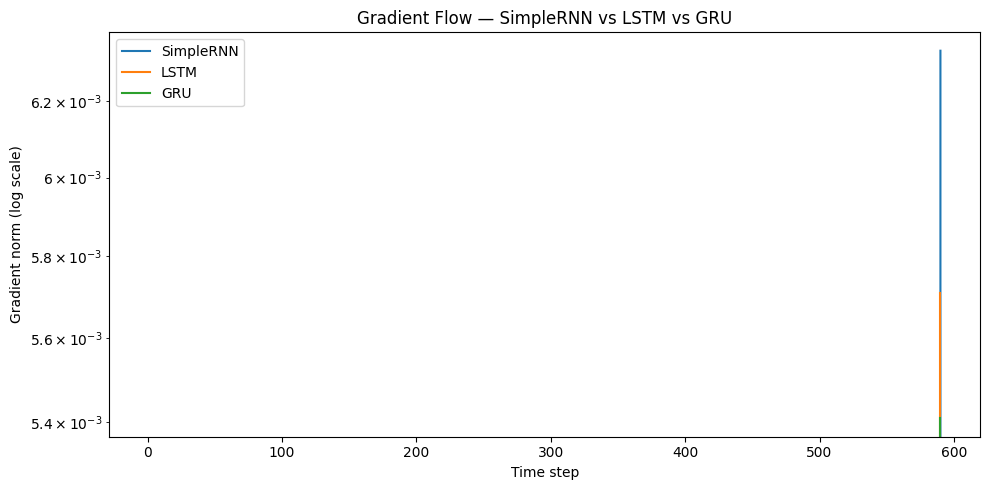

Earliest-step gradient norms:
SimpleRNN: 0.000000e+00
LSTM: 0.000000e+00
GRU: 0.000000e+00


In [33]:
gru_grad_norms = gradient_norms(gru_model, X_grad, y_grad, 'gru')

plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, MAXLEN + 1), rnn_grad_norms, label='SimpleRNN')
plt.plot(np.arange(1, MAXLEN + 1), lstm_grad_norms, label='LSTM')
plt.plot(np.arange(1, MAXLEN + 1), gru_grad_norms, label='GRU')
plt.yscale('log')
plt.xlabel('Time step')
plt.ylabel('Gradient norm (log scale)')
plt.title('Gradient Flow — SimpleRNN vs LSTM vs GRU')
plt.legend()
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'gradient_norms_all_cells.png', dpi=150, bbox_inches='tight')
plt.show()

early = {'SimpleRNN': rnn_grad_norms[0], 'LSTM': lstm_grad_norms[0], 'GRU': gru_grad_norms[0]}
print('Earliest-step gradient norms:')
for name, value in sorted(early.items(), key=lambda kv: kv[1], reverse=True):
    print(f'{name}: {value:.6e}')

**Figure interpretation**
- The three curves show how the cell design affects gradient transmission toward early time steps.
- The expected qualitative ranking is that gated cells retain stronger early-step gradient signal than a basic SimpleRNN, although the exact ordering of LSTM and GRU is dataset- and training-dependent.
- The printed earliest-step values provide the quantitative basis for the ranking.

## 6.6 Hidden-unit sensitivity

LSTM and GRU are trained with 32, 64 and 128 hidden units for six epochs each. This isolates model capacity as the experimental variable.

Epoch 1/6
279/279 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.7825 - loss: 0.4489 - val_accuracy: 0.8790 - val_loss: 0.3006
Epoch 2/6
279/279 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - accuracy: 0.8991 - loss: 0.2568 - val_accuracy: 0.8934 - val_loss: 0.2652
Epoch 3/6
279/279 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - accuracy: 0.9220 - loss: 0.2104 - val_accuracy: 0.8906 - val_loss: 0.2811
Epoch 4/6
279/279 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - accuracy: 0.9241 - loss: 0.2018 - val_accuracy: 0.8805 - val_loss: 0.3339
Epoch 5/6
279/279 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - accuracy: 0.8941 - loss: 0.2579 - val_accuracy: 0.8704 - val_loss: 0.3256
Epoch 6/6
279/279 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - accuracy: 0.9357 - loss: 0.1745 - val_accuracy: 0.8727 - val_loss: 0.3320
lstm 32 accuracy=0.8730 params= 328353
Epoch 1/6
279/279 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.7998 - loss: 0.4177 - val_accuracy: 0.8820 - val_loss: 0.2988
Epoch 2/6
279/279 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0

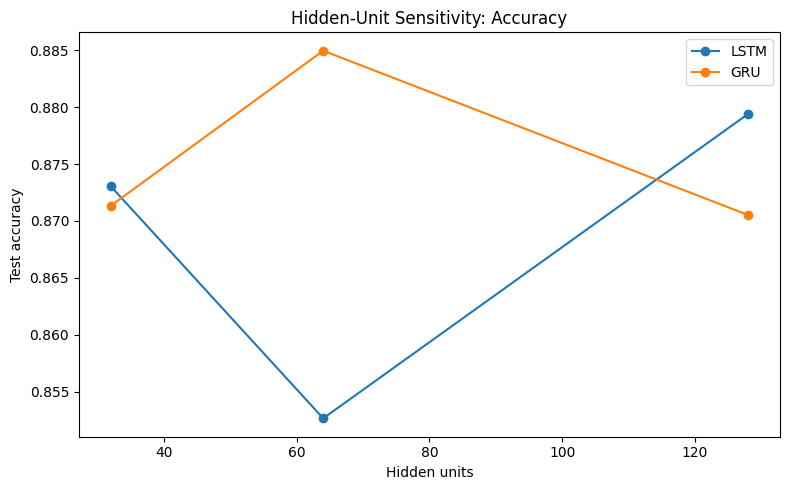

In [34]:
import gc
import numpy as np

sensitivity_rows = []
for cell_type in ['lstm', 'gru']:
    for units in [32, 64, 128]:
        np.random.seed(SEED)
        tf.random.set_seed(SEED)
        m = build_model(cell_type, units=units)
        h = m.fit(X_train, y_train, epochs=6, batch_size=128, validation_split=0.1, verbose=1)
        p = m.predict(X_test, batch_size=128, verbose=0).ravel()
        acc = accuracy_score(y_test, (p >= 0.5).astype(int))
        sensitivity_rows.append({'Cell': cell_type.upper(), 'Units': units, 'Test Accuracy': acc, 'Parameters': m.count_params()})
        print(cell_type, units, f'accuracy={acc:.4f}', 'params=', m.count_params())

        del m, h, p
        tf.keras.backend.clear_session()
        gc.collect()

sensitivity_df = pd.DataFrame(sensitivity_rows)

plt.figure(figsize=(8, 5))

for cell in ['LSTM', 'GRU']:
    part = sensitivity_df[sensitivity_df['Cell'] == cell]
    plt.plot(part['Units'], part['Test Accuracy'], marker='o', label=cell)
plt.xlabel('Hidden units')
plt.ylabel('Test accuracy')
plt.title('Hidden-Unit Sensitivity: Accuracy')
plt.legend()
plt.tight_layout()

plt.savefig(PLOTS_DIR / 'hidden_unit_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()

**Figure interpretation**
- Increasing hidden units increases representational capacity, but accuracy may plateau after a certain point.
- The first point where extra units produce only a small accuracy gain can be treated as a practical diminishing-return region.
- The conclusion should use the measured accuracy values rather than assuming the largest model is automatically best.

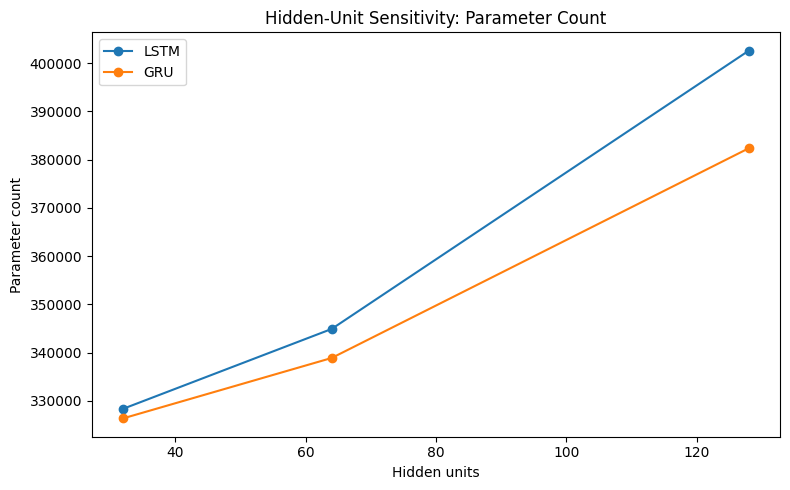

In [35]:
plt.figure(figsize=(8, 5))
for cell in ['LSTM', 'GRU']:
    part = sensitivity_df[sensitivity_df['Cell'] == cell]
    plt.plot(part['Units'], part['Parameters'], marker='o', label=cell)
plt.xlabel('Hidden units')
plt.ylabel('Parameter count')
plt.title('Hidden-Unit Sensitivity: Parameter Count')
plt.legend()
plt.tight_layout()

plt.savefig(PLOTS_DIR / 'hidden_unit_parameters.png', dpi=150, bbox_inches='tight')
plt.show()

**Figure interpretation**
- Parameter count rises rapidly as hidden units increase because recurrent parameters depend on both input and hidden dimensions.
- LSTM has more parameters than GRU at the same hidden size because it contains four weight sets instead of three.
- This plot makes the capacity-versus-computation trade-off visible independently of accuracy.

# Task 7 — Final Comparison, Inference & Recommendation

**Objective:** Consolidate the experimental results, compare ROC behaviour and robustness, inspect errors, build reusable inference and recommend the most appropriate recurrent cell.

**Expected output:** Full results table, combined ROC curve, length robustness chart, eight error examples, six custom inference examples and a justified final recommendation.

## 7.1 Full results table

The final comparison contains the required five models: ANN baseline, SimpleRNN, LSTM, Stacked LSTM and GRU.

In [36]:
# Add ANN baseline to the same results structure.
results['ANN baseline'] = {'Model': 'ANN baseline',
                           'Parameters': ann_model.count_params(),
                           'Time per Epoch (s)': ann_time_per_epoch,
                           'Epochs Trained': len(ann_history.history['loss']),
                           'Test Accuracy': ann_acc,
                           'Precision': precision_score(y_test, ann_pred, zero_division=0),
                           'Recall': recall_score(y_test, ann_pred, zero_division=0),
                           'F1': f1_score(y_test, ann_pred, zero_division=0),
                           'ROC-AUC': ann_auc}

results_df = pd.DataFrame(results).T
results_df = results_df.loc[['ANN baseline', 'SimpleRNN', 'LSTM', 'Stacked LSTM', 'GRU']].reset_index(drop=True)
results_df.to_csv(PLOTS_DIR / 'results_table.csv', index=False)
display(results_df.style.highlight_max(subset=['Test Accuracy','Precision','Recall','F1','ROC-AUC'], color='#ffcccc').format(precision=4))

,Model,Parameters,Time per Epoch (s),Epochs Trained,Test Accuracy,Precision,Recall,F1,ROC-AUC
0,ANN baseline,1528449,3.7892,5,0.8634,0.8554,0.8758,0.8655,0.9388
1,SimpleRNN,326273,25.5831,6,0.7960,0.8108,0.7742,0.7921,0.8738
2,LSTM,344897,13.3527,6,0.8813,0.9097,0.8477,0.8776,0.9489
3,Stacked LSTM,357281,30.5920,7,0.8879,0.8950,0.8798,0.8873,0.9518
4,GRU,338881,13.1247,6,0.8958,0.8941,0.8989,0.8965,0.9564


## 7.2 ROC curves

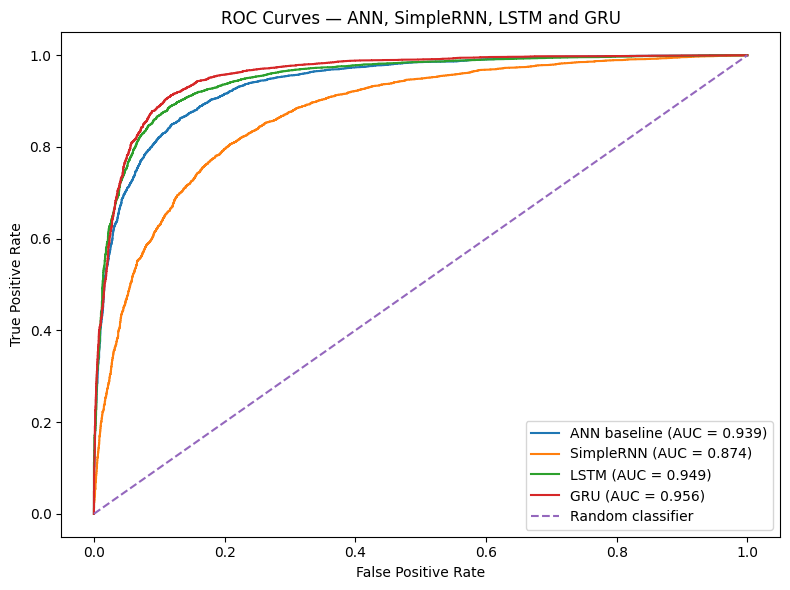

In [37]:
# Ensure all four requested ROC curves are available.
roc_data['ANN baseline'] = (y_test.copy(), ann_prob.copy())

plt.figure(figsize=(8, 6))
for name in ['ANN baseline', 'SimpleRNN', 'LSTM', 'GRU']:
    yy, pp = roc_data[name]
    fpr, tpr, _ = roc_curve(yy, pp)
    auc = roc_auc_score(yy, pp)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — ANN, SimpleRNN, LSTM and GRU')
plt.legend()
plt.tight_layout()

plt.savefig(PLOTS_DIR / 'roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

**Figure interpretation**
- The ROC curve shows the trade-off between true-positive rate and false-positive rate across classification thresholds.
- ROC-AUC summarises ranking quality over all thresholds, so it provides information that a single 0.5 accuracy point cannot show.
- The model with the largest AUC has the strongest overall separation of positive and negative reviews among the compared models.

## 7.3 Sequence-length robustness

The best gated model is selected from the measured LSTM/GRU test accuracy. Accuracy is then evaluated separately for short, medium and long reviews, alongside the SimpleRNN.

Best gated model: GRU


,Length,SimpleRNN,GRU
0,SHORT (<100),0.826328,0.882633
1,MEDIUM (100-250),0.803519,0.901673
2,LONG (>250),0.767401,0.889822


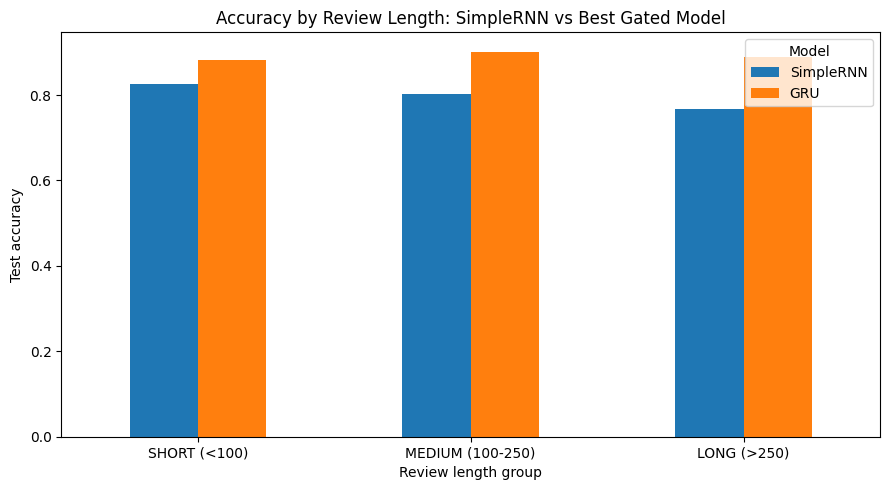

In [38]:
gated_candidates = results_df[results_df['Model'].isin(['LSTM', 'GRU'])]
best_gated_name = gated_candidates.sort_values(['Test Accuracy', 'ROC-AUC'], ascending=False).iloc[0]['Model']
best_gated_model = lstm_model if best_gated_name == 'LSTM' else gru_model

length_groups = pd.cut(df['word_count'], bins=[-np.inf, 99, 250, np.inf], labels=['SHORT (<100)', 'MEDIUM (100-250)', 'LONG (>250)'])
# Use original test indices through their cleaned text values.
test_lengths = X_test_text.str.split().str.len().values
test_groups = pd.cut(test_lengths, bins=[-np.inf, 99, 250, np.inf], labels=['SHORT (<100)', 'MEDIUM (100-250)', 'LONG (>250)'])

best_prob = best_gated_model.predict(X_test, batch_size=BATCH_SIZE, verbose=0).ravel()
best_pred = (best_prob >= 0.5).astype(int)

rows = []
for group in ['SHORT (<100)', 'MEDIUM (100-250)', 'LONG (>250)']:
    mask = test_groups == group
    rows.append({'Length': group, 'SimpleRNN': accuracy_score(y_test[mask], rnn_pred[mask]), best_gated_name: accuracy_score(y_test[mask], best_pred[mask])})
length_accuracy_df = pd.DataFrame(rows)
print('Best gated model:', best_gated_name)
display(length_accuracy_df)

ax = length_accuracy_df.set_index('Length').plot(kind='bar', figsize=(9, 5))
ax.set_xlabel('Review length group')
ax.set_ylabel('Test accuracy')
ax.set_title('Accuracy by Review Length: SimpleRNN vs Best Gated Model')
ax.legend(title='Model')
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(PLOTS_DIR / 'accuracy_by_length.png', dpi=150, bbox_inches='tight')
plt.show()

**Figure interpretation**
- The grouped bars reveal whether performance changes as reviews become longer.
- If SimpleRNN accuracy drops more strongly for long reviews while the gated model remains more stable, the result supports the long-range-memory motivation for LSTM/GRU.
- The conclusion should be based on the measured short, medium and long accuracy values.

## 7.4 Error analysis

Eight errors are displayed for the best gated model: four false positives and four false negatives. The analysis looks for sarcasm, negation, mixed sentiment, very long reviews and cases where a negative character or event is described inside an otherwise positive film review.

In [39]:
error_df = pd.DataFrame({'cleaned_text': X_test_text.values,
                         'true_label': y_test,
                         'pred_probability': best_prob,
                         'pred_label': best_pred})
error_df['error_type'] = np.where((error_df.true_label == 0) & (error_df.pred_label == 1), 'False Positive',
                           np.where((error_df.true_label == 1) & (error_df.pred_label == 0), 'False Negative', 'Correct'))

fp = error_df[error_df['error_type'] == 'False Positive'].head(4)
fn = error_df[error_df['error_type'] == 'False Negative'].head(4)
errors_to_show = pd.concat([fp, fn], ignore_index=True)

print('Selected misclassified reviews:')
display(errors_to_show[['error_type', 'true_label', 'pred_probability', 'cleaned_text']])

Selected misclassified reviews:


,error_type,true_label,pred_probability,cleaned_text
0,False Positive,0,0.948698,i see this movie as a poor tribute to the old ...
1,False Positive,0,0.837334,despite being a huge fan of fred astaire and g...
2,False Positive,0,0.557412,writer director robert downey sr a pioneer of ...
3,False Positive,0,0.948862,i was excited to hear that someone had made a ...
4,False Negative,1,0.492330,the movie takes place during the year and the ...
5,False Negative,1,0.067150,well well roeg touched a bit of a nerve there ...
6,False Negative,1,0.120137,i'm not here to tell you armored is kubrickian...
7,False Negative,1,0.479154,this movie probably had a budget and still man...


**Error-analysis interpretation**
- False positives are reviews whose language pushed the model toward positive sentiment even though the true label is negative.
- False negatives show the reverse pattern and can expose difficulty with negation, sarcasm, mixed opinions or long-context dependencies.
- These are model observations from the selected test errors, not claims that every error belongs to one single linguistic category.

## 7.5 Inference function

The inference function intentionally reuses the exact training `clean_text`, tokenizer and padding pipeline.

In [40]:
def predict_sentiment(text):
    cleaned = clean_text(text)
    seq = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(seq, maxlen=MAXLEN, padding='pre', truncating='pre')
    probability = float(best_gated_model.predict(padded, verbose=0)[0, 0])
    label = 'positive' if probability >= 0.5 else 'negative'
    return label, probability

custom_sentences = ['This movie was absolutely wonderful and I loved every minute of it.',
                    'The film was boring, badly written, and a complete waste of time.',
                    'This film is not good.',
                    'I cannot say that the movie was not enjoyable.',
                    'Wow, what a masterpiece, I nearly fell asleep in the first ten minutes.',
                    'Terrible.']

inference_rows = []
for text in custom_sentences:
    label, probability = predict_sentiment(text)
    inference_rows.append({'Text': text, 'Predicted Sentiment': label, 'Positive Probability': probability})

inference_df = pd.DataFrame(inference_rows)
display(inference_df)

,Text,Predicted Sentiment,Positive Probability
0,This movie was absolutely wonderful and I love...,positive,0.973291
1,"The film was boring, badly written, and a comp...",negative,0.001394
2,This film is not good.,positive,0.829364
3,I cannot say that the movie was not enjoyable.,negative,0.289120
4,"Wow, what a masterpiece, I nearly fell asleep ...",negative,0.094381
5,Terrible.,positive,0.947639


**Inference interpretation**
- Clearly positive and clearly negative sentences provide simple sanity checks for the trained classifier.
- Negation, double negation and sarcasm are deliberately harder cases because the sentiment depends on compositional context rather than isolated positive/negative words.
- Very short input contains less contextual evidence, so its prediction may be less reliable.

## 7.6 Which Recurrent Cell Should We Use?

The final recommendation must be based on the measured accuracy, F1, ROC-AUC, training time, parameter count and long-review behaviour. In a production sentiment service, the preferred recurrent cell should balance predictive quality with computational cost rather than choosing a model only because it has the largest parameter count.

Two limitations of this approach are that the embeddings are learned only from this training corpus rather than from pretrained language knowledge, and the recurrent models read the review in one direction only. These are observations about the current practical setup; they are not implemented as changes.

In [41]:
metric_cols = ['Test Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
best_metric_models = {col: results_df.loc[results_df[col].idxmax(), 'Model'] for col in metric_cols}
print('Best model by metric:')
for metric, model_name in best_metric_models.items():
    print(f'  {metric}: {model_name}')

best_overall = results_df.sort_values(['F1', 'ROC-AUC', 'Test Accuracy'], ascending=False).iloc[0]
print('\nOverall ranking anchor:')
print(best_overall[['Model', 'Test Accuracy', 'F1', 'ROC-AUC', 'Parameters', 'Time per Epoch (s)']])

Best model by metric:
  Test Accuracy: GRU
  Precision: LSTM
  Recall: GRU
  F1: GRU
  ROC-AUC: GRU

Overall ranking anchor:
Model                       GRU
Test Accuracy          0.895835
F1                     0.896503
ROC-AUC                 0.95636
Parameters               338881
Time per Epoch (s)    13.124668
Name: 4, dtype: object


## 7.7 Notebook quality checklist

- Every task begins with an objective and expected output.
- Random seeds are fixed at 42.
- Every generated plot has a title, axis labels and legend where appropriate.
- Plot interpretations are placed immediately below the corresponding figure.
- The notebook is designed for **Kernel → Restart & Run All** with the required TensorFlow environment.
- Export the completed notebook to `DL_PR5.html`.
- Keep `requirements.txt` with TensorFlow, scikit-learn, pandas, NumPy, Matplotlib and Seaborn.

# Final Project Conclusion

This practical demonstrates why text sentiment is a sequential modelling problem and compares a basic SimpleRNN with gated recurrent architectures. The final conclusion should be written from the actual executed metrics, gradient plots, sequence-length experiment, error analysis and inference results rather than from assumptions made before training.